In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

In [3]:
train = pd.read_csv("FNN and CNN/Sign Language MNIST/sign_mnist_test.csv")
test = pd.read_csv("FNN and CNN/Sign Language MNIST/sign_mnist_test.csv")

print(train.shape)
print(test.shape)

(7172, 785)
(7172, 785)


In [4]:
x_train = train[train["label"] != 24].drop("label", axis=1)

x_test = test.drop("label", axis=1)
y_test = (test["label"] == 24).astype(int)

In [5]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [6]:
model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(64, activation="relu"),
    Dense(128, activation="relu"),
    Dense(784, activation="sigmoid")
])

model.compile(optimizer="adam", loss="mse")

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = model.fit(
    x_train, x_train,
    epochs=20,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0341 - val_loss: 0.0297
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0267 - val_loss: 0.0267
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0224 - val_loss: 0.0228
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0193 - val_loss: 0.0199
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0171 - val_loss: 0.0163
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0153 - val_loss: 0.0159
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0145 - val_loss: 0.0144
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0136 - val_loss: 0.0137
Epoch 9/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0130 - val_loss: 0.0156
Epoch 10/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0130 - val_loss: 0.0132
Epoch 11/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0119 - val_loss: 0.0120
Epoch 12/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0114 - val_lo

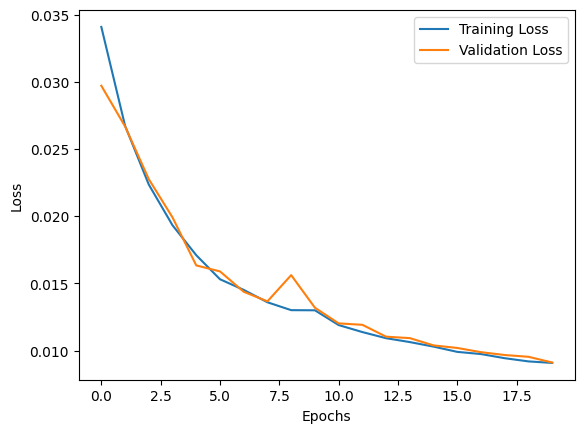

In [8]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [9]:
train_pred = model.predict(x_train)

train_error = np.mean(np.square(x_train - train_pred), axis=1)

threshold = np.mean(train_error) + 3 * np.std(train_error)

print("Threshold:", threshold)

214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 573us/step
Threshold: 0.020509574845428258


In [10]:
test_pred = model.predict(x_test)

test_error = np.mean(np.square(x_test - test_pred), axis=1)

y_pred = (test_error > threshold).astype(int)

print("Detected Anomalies:", np.sum(y_pred))

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 485us/step
Detected Anomalies: 107


In [11]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[6759   81]
 [ 306   26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.97      6840
           1       0.24      0.08      0.12       332

    accuracy                           0.95      7172
   macro avg       0.60      0.53      0.55      7172
weighted avg       0.92      0.95      0.93      7172

